# What do unhappy bank-app users write about, and what should be fixed first?

**Reader:** head of digital product or customer experience at a bank. **Decision:** which app problems to fix first to reduce low-rated reviews, and how complaints about banks differ from those about fintech and payment apps.
**Data:** the 500 most recent App Store reviews (US, iOS) of 17 bank, card and fintech apps, collected 2026-10-26 (8,350 reviews). The plan, validation method and predictions were written before the analysis in [research_plan.md](../research_plan.md). Reviewer names and IDs were never stored, and review text is not included in the repo.

## Answer in brief
- **Most unhappy reviewers write about the app working or changing, not about the bank.** Among 1 and 2 star reviews at banks, **37%** mention login or bugs, and **59%** mention login, bugs or a redesign or update.
- **Common is not the same as costly.** Updates and design are the most frequent theme among unhappy reviewers (27%) but the weakest link to a low rating (odds ratio 1.7). **Frozen or closed accounts** are rare at banks (3%) but the strongest (odds ratio **12.8**); login (4.1) and bugs (3.9) are both common and strongly linked.
- **Fintech and payment apps have a different problem.** Their unhappy reviewers mention frozen or closed accounts **2.7 times** and fraud or security **3.5 times** as often as bank and card-issuer reviewers, and write more about payments and customer service.
- **Average rating is not a quality measure here.** The mean rating of recent reviews runs from 1.6 to 4.8 stars across apps, but it tracks how many short five-star reviews an app collects (correlation 0.99 with its share of five-star reviews), which depends on how often it prompts happy users.
- **The theme tagger is moderate, not precise** (median precision 0.75 and recall 0.71 on fresh reviews), so shares are approximate and comparisons between groups are more reliable than exact percentages.

In [1]:
import sys, warnings; sys.path.insert(0, "../src"); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import reviews as rv, themes

NAVY, ORANGE, GREY, RED, TEAL = "#2f4b7c", "#e08b3a", "#8a8f98", "#c0504d", "#4aa3a2"
GROUPS = ["Banks & credit unions", "Card issuers", "Fintech & digital banks"]
GCOL = dict(zip(GROUPS, [NAVY, TEAL, ORANGE]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = "../reports/figures/"
raw = pd.read_csv(rv.RAW, parse_dates=["date"])
d = rv.load(min_words=4)
low = d[d.low]

## 1. The sample, and why average rating can't be compared

In [2]:
g = raw.groupby("app").agg(group=("group", "first"), reviews=("rating", "size"), first=("date", "min"), last=("date", "max"), mean_rating=("rating", "mean"),
                           five_star=("rating", lambda s: (s == 5).mean()), low_star=("rating", lambda s: (s <= 2).mean()),
                           short=("text", lambda s: (s.str.split().str.len() < 6).mean()))
g["window_days"] = (g["last"] - g["first"]).dt.days + 1
show = g.sort_values("window_days")[["group", "reviews", "window_days", "mean_rating", "five_star", "low_star", "short"]]
print(show.round(2).to_string())
print(f"\nReviews collected: {len(raw):,} | with 4+ words: {len(d):,} | low-rated (1-2 stars) with 4+ words: {len(low):,}")
rho = g[["window_days", "mean_rating", "five_star", "short"]].corr(method="spearman")
print("\nSpearman correlations across apps:"); print(rho.round(2).to_string())

                                    group  reviews  window_days  mean_rating  five_star  low_star  short
app                                                                                                     
U.S. Bank           Banks & credit unions      500            3         4.72       0.89      0.06   0.42
Truist              Banks & credit unions      450           11         4.80       0.90      0.04   0.44
Venmo             Fintech & digital banks      500           12         1.57       0.10      0.87   0.14
Capital One         Banks & credit unions      500           17         3.51       0.55      0.35   0.22
Wells Fargo         Banks & credit unions      500           19         4.41       0.81      0.13   0.44
Chase               Banks & credit unions      500           22         3.22       0.47      0.41   0.21
Cash App          Fintech & digital banks      500           22         3.45       0.55      0.36   0.35
Chime             Fintech & digital banks      500     

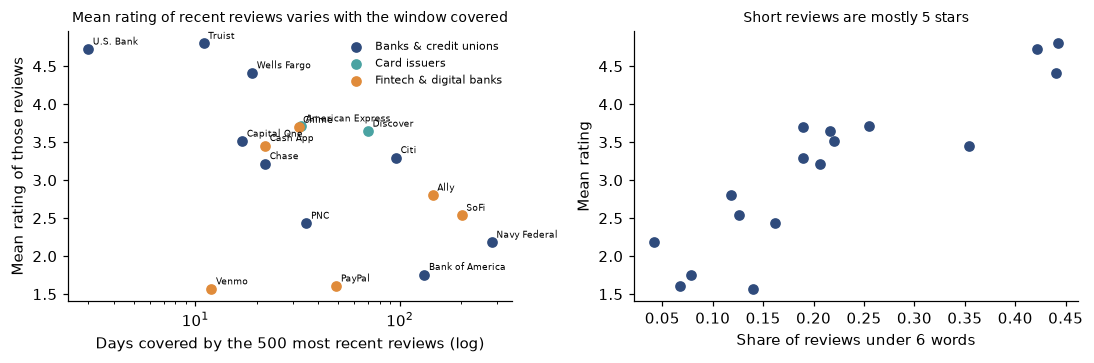

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for grp in GROUPS:
    s = g[g.group == grp]; ax[0].scatter(s.window_days, s.mean_rating, color=GCOL[grp], label=grp, s=36)
for name, r in g.iterrows(): ax[0].annotate(name, (r.window_days, r.mean_rating), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax[0].set_xscale("log"); ax[0].set_xlabel("Days covered by the 500 most recent reviews (log)"); ax[0].set_ylabel("Mean rating of those reviews"); ax[0].legend(frameon=False, fontsize=7)
ax[0].set_title("Mean rating of recent reviews varies with the window covered", fontsize=9)
ax[1].scatter(g.short, g.mean_rating, color=NAVY, s=36); ax[1].set_xlabel("Share of reviews under 6 words"); ax[1].set_ylabel("Mean rating")
ax[1].set_title("Short reviews are mostly 5 stars", fontsize=9)
plt.tight_layout(); plt.savefig(FIG + "sampling.png"); plt.show()

In [4]:
v = raw[raw.app == "Venmo"]; vd = v.groupby("date").agg(n=("rating", "size"), low_share=("rating", lambda s: (s <= 2).mean()))
print("Venmo, share of reviews rated 1-2 stars by day:"); print(vd.round(2).T.to_string())
print("\nAcross all apps, share of recent reviews rated 1-2 stars on the single worst day vs the app's overall share (days with 20+ reviews):")
dd = raw.groupby(["app", "date"]).agg(n=("rating", "size"), low=("rating", lambda s: (s <= 2).mean())).reset_index(); dd = dd[dd.n >= 20]
print(dd.groupby("app").agg(days=("date", "size"), min_low=("low", "min"), max_low=("low", "max")).round(2).to_string())

Venmo, share of reviews rated 1-2 stars by day:
date       2026-10-14  2026-10-15  2026-10-16  2026-10-17  2026-10-18  2026-10-19  2026-10-20  2026-10-21  2026-10-22  2026-10-23  2026-10-24  2026-10-25
n               44.00        55.0       37.00       43.00       43.00       35.00       45.00       49.00        51.0       49.00        46.0         3.0
low_share        0.98         0.8        0.86        0.88        0.91        0.83        0.89        0.82         0.9        0.86         0.8         1.0

Across all apps, share of recent reviews rated 1-2 stars on the single worst day vs the app's overall share (days with 20+ reviews):
                  days  min_low  max_low
app                                     
American Express     3     0.15     0.72
Capital One         15     0.15     0.57
Cash App            17     0.21     0.52
Chase               17     0.09     0.61
Chime                8     0.13     0.39
PNC                  8     0.42     0.72
PayPal               1     0

The 500 most recent reviews cover wildly different time spans: **3 days for U.S. Bank, 282 days for Navy Federal**. Apps that ask satisfied users to rate fill their window quickly with short five-star reviews, so the window is short and the mean rating high; apps that don't, accumulate older, unhappier reviews. Across apps, mean rating correlates 0.99 with the share of five-star reviews and 0.89 with the share of very short reviews. **I therefore don't compare apps on mean rating, and the main analysis uses only 1 and 2 star reviews**, whose authors write spontaneously.

Venmo's low ratings are not a one-day burst: between 80% and 98% of its reviews were rated 1 or 2 stars on each of the 11 days with at least 20 reviews, across two app versions.

## 2. How well does the tagger work?
Reviews are tagged by transparent keyword rules for nine themes (a review can have several). I read and labeled 200 reviews myself, **as an AI, not a second human**, before running the tagger on them. Version 1 of the rules scored poorly on a first sample (precision from 0.47 to 0.95, recall from 0.35 to 0.91). I rewrote them after error analysis on that sample (praise now needs a 4 or 5 star rating, "scam" as an insult to the company no longer counts as a fraud report, a frozen screen is no longer a frozen account, and so on), then scored version 2 **once on a fresh sample of 200 unseen reviews**:

In [5]:
# Tagger quality on hand-labeled reviews. Labels were made by reading each review (by an AI, not a second human) before running the tagger.
A = pd.read_csv("../data/processed/validation_labels.csv").fillna(""); Bv = pd.read_csv("../data/processed/validation_labels_B.csv").fillna("")
codes = {"L": "Login & authentication", "B": "Bugs, crashes & slowness", "F": "Fraud, scams & security", "Z": "Frozen, closed or restricted accounts", "S": "Customer service & support",
         "E": "Fees & charges", "P": "Payments, transfers & deposits", "U": "Updates, design & features", "G": "Praise & ease of use"}
def score(order_file, labels, tagger_frame):
    allr = raw.reset_index(drop=True); allr["rid"] = allr.index
    v = allr.set_index("rid").loc[pd.read_csv(order_file).rid].reset_index(drop=True)
    truth = pd.DataFrame({n: [c in s.split(";") for s in labels.labels] for c, n in codes.items()})
    pred = tagger_frame(v)[list(codes.values())]
    rows = []
    for n in codes.values():
        t, p = truth[n].values, pred[n].values; tp, fp, fn = (t & p).sum(), (~t & p).sum(), (t & ~p).sum()
        rows.append({"theme": n, "labeled": int(t.sum()), "precision": tp / (tp + fp) if tp + fp else np.nan, "recall": tp / (tp + fn) if tp + fn else np.nan})
    return pd.DataFrame(rows).set_index("theme")
resB = score("../data/processed/validation_order_B.csv", Bv, themes.tag_frame)
print("Final tagger (v2) on fresh sample B, scored once (200 reviews: 150 low-rated + 50 high-rated):"); print(resB.round(2).to_string())
print(f"\nPrecision at least 0.8 for {(resB.precision >= 0.8).sum()} of 9 themes; median precision {resB.precision.median():.2f}; median recall {resB.recall.median():.2f}")

Final tagger (v2) on fresh sample B, scored once (200 reviews: 150 low-rated + 50 high-rated):
                                       labeled  precision  recall
theme                                                            
Login & authentication                      13       0.67    0.92
Bugs, crashes & slowness                    42       0.82    0.64
Fraud, scams & security                     14       0.70    0.50
Frozen, closed or restricted accounts       17       0.75    0.71
Customer service & support                  39       0.70    0.72
Fees & charges                              13       0.90    0.69
Payments, transfers & deposits              43       0.59    0.74
Updates, design & features                  55       0.81    0.71
Praise & ease of use                        47       0.93    0.89

Precision at least 0.8 for 4 of 9 themes; median precision 0.75; median recall 0.71


The tagger is usable for comparing groups but not exact: precision is 0.8 or better for 4 of 9 themes (median 0.75) and recall is 0.50 to 0.92 (median 0.71). The weakest are payments and transfers (precision 0.59: the words are everywhere), login (precision 0.67) and fraud (recall 0.50: reviewers describe fraud in many ways). Errors are likely similar across groups, so ratios between groups are more trustworthy than exact shares.

## 3. What unhappy reviewers write about
Shares are among **1 and 2 star reviews with four or more words** (3,691 reviews).

In [6]:
prev_g = rv.prevalence(low, "group")
tab = prev_g.pivot(index="theme", columns="group", values="share")[GROUPS]
tab["All low-rated"] = [low[c].mean() for c in tab.index]
tab = tab.loc[tab["All low-rated"].sort_values(ascending=False).index]
print(f"Share of 1-2 star reviews mentioning each theme (n = {low.groupby('group').size().to_dict()}):"); print((100 * tab).round(0).astype(int).rename(index=rv.SHORT).to_string())
print(f"\nAt least one problem theme: {low[rv.PROBLEM].any(axis=1).mean():.0%} of low-rated reviews")

Share of 1-2 star reviews mentioning each theme (n = {'Banks & credit unions': 1680, 'Card issuers': 276, 'Fintech & digital banks': 1735}):
group                     Banks & credit unions  Card issuers  Fintech & digital banks  All low-rated
theme                                                                                                
Updates & design                             33            18                       24             27
Payments & transfers                         23            14                       31             26
Bugs & slowness                              27            12                       17             21
Customer service                             15            12                       26             20
Login                                        19            13                       14             16
Frozen / closed accounts                      3             7                       10              7
Fees & charges                             

In [7]:
bk = low[low.group == "Banks & credit unions"]
lb = bk["Login & authentication"] | bk["Bugs, crashes & slowness"]
lbu = lb | bk["Updates, design & features"]
print(f"Banks & credit unions, 1-2 star reviews (n={len(bk):,}): login OR bugs in {lb.mean():.0%}; login OR bugs OR updates/design in {lbu.mean():.0%}")

Banks & credit unions, 1-2 star reviews (n=1,680): login OR bugs in 37%; login OR bugs OR updates/design in 59%


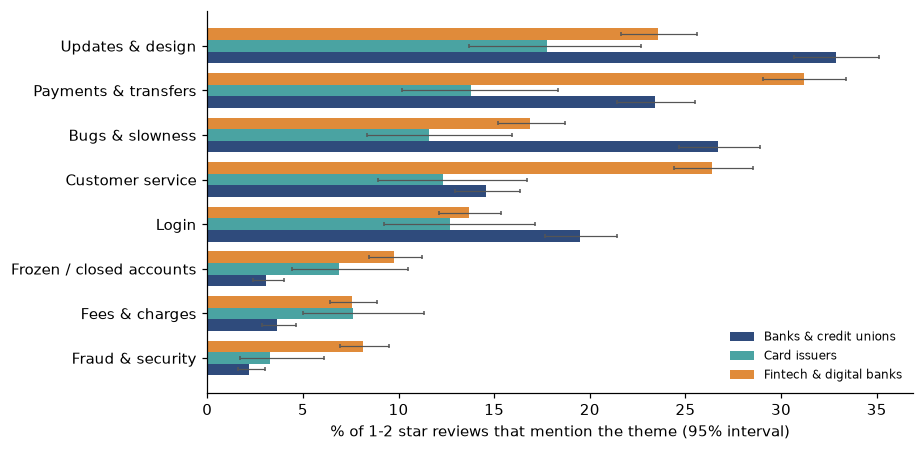

In [8]:
order = tab.index[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.2)); h = 0.26
for i, grp in enumerate(GROUPS):
    s = prev_g[prev_g.group == grp].set_index("theme").loc[order]
    y = np.arange(len(order)) + (i - 1) * h
    ax.barh(y, 100 * s.share, h, color=GCOL[grp], label=grp, xerr=[100 * (s.share - s.lo), 100 * (s.hi - s.share)], error_kw=dict(lw=0.8, capsize=1.5, ecolor="#555"))
ax.set_yticks(range(len(order)), [rv.SHORT[o] for o in order]); ax.set_xlabel("% of 1-2 star reviews that mention the theme (95% interval)"); ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIG + "themes_by_group.png"); plt.show()

In [9]:
# What share of unhappy reviewers write about the two things that matter for the scam analysis, by group?
fz = low.assign(fraud_or_frozen=low["Fraud, scams & security"] | low["Frozen, closed or restricted accounts"]).groupby("group").fraud_or_frozen.agg(["mean", "size", "sum"])
fz["lo"], fz["hi"] = rv.wilson(fz["sum"], fz["size"])
print("Fraud/security OR frozen/closed-account mentions among 1-2 star reviews:"); print(fz[["mean", "lo", "hi", "size"]].round(3).to_string())
ft = low.assign(group2=np.where(low.group == "Fintech & digital banks", "Fintech & digital banks", "Banks, credit unions & card issuers"))
for c in ["Frozen, closed or restricted accounts", "Fraud, scams & security"]:
    t = ft.groupby("group2")[c].agg(["mean", "sum", "size"]); rr = t.loc["Fintech & digital banks", "mean"] / t.loc["Banks, credit unions & card issuers", "mean"]
    print(f"{rv.SHORT[c]}: fintech {t.loc['Fintech & digital banks','mean']:.1%} vs banks and card issuers {t.loc['Banks, credit unions & card issuers','mean']:.1%} (ratio {rr:.1f}x)")

Fraud/security OR frozen/closed-account mentions among 1-2 star reviews:
                          mean     lo     hi  size
group                                             
Banks & credit unions    0.053  0.043  0.065  1680
Card issuers             0.094  0.065  0.134   276
Fintech & digital banks  0.168  0.151  0.187  1735
Frozen / closed accounts: fintech 9.7% vs banks and card issuers 3.6% (ratio 2.7x)
Fraud & security: fintech 8.1% vs banks and card issuers 2.4% (ratio 3.5x)


- **78%** of unhappy reviews mention at least one of the eight problem themes. The most common are updates and design (27%), payments and transfers (26%), bugs and slowness (21%), customer service (20%) and login (16%); frozen or closed accounts (7%), fees (6%) and fraud or security (5%) are rarer.
- **At banks and credit unions** the leading themes are updates and design (33%), bugs and slowness (27%) and payments (23%); **37%** mention login or bugs, and **59%** mention login, bugs or a redesign or update.
- **At fintech and digital banks** the order differs: payments and transfers (31%), customer service (26%), then updates (24%). Frozen or closed accounts (10%) and fraud or security (8%) are far more prominent.
- **The scam link:** among unhappy reviewers, 16.8% of fintech reviews mention fraud, security or a frozen or closed account, against 5.3% at banks and 9.4% at card issuers. Fraud and security are 3.5 times as common at fintech (8.1% against 2.4%) and frozen or closed accounts 2.7 times (9.7% against 3.6%) than at banks and card issuers combined. This fits the scam-complaint analysis, where payment and fintech companies range from 0% (Cash App) to 20% (PayPal) monetary relief on scam complaints, but reviews alone can't show why.

## 4. Each app against its peers

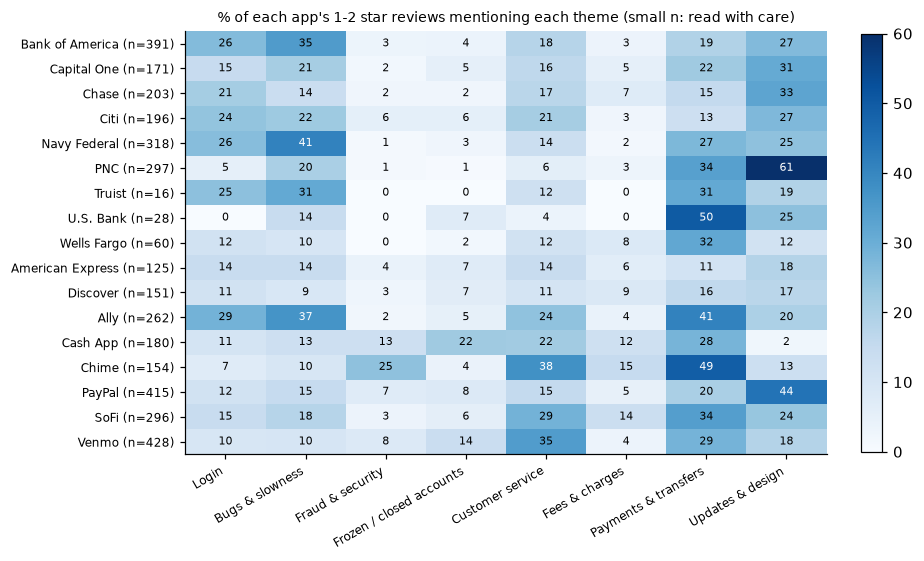

Apps with fewer than 50 low-rated reviews (too few for per-app conclusions): ['Truist', 'U.S. Bank']


In [10]:
by_app = rv.prevalence(low, "app"); n_app = low.groupby("app").size()
heat = by_app.pivot(index="app", columns="theme", values="share")[rv.PROBLEM]
heat = heat.loc[low.groupby("app").group.first().map({g_: i for i, g_ in enumerate(GROUPS)}).sort_values(kind="stable").index]
fig, ax = plt.subplots(figsize=(8.5, 5.2)); im = ax.imshow(100 * heat.values, cmap="Blues", aspect="auto", vmin=0, vmax=60)
ax.set_xticks(range(len(rv.PROBLEM)), [rv.SHORT[c] for c in rv.PROBLEM], rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(heat)), [f"{a} (n={n_app[a]})" for a in heat.index], fontsize=8)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]): ax.text(j, i, f"{100*heat.values[i, j]:.0f}", ha="center", va="center", fontsize=7, color="white" if heat.values[i, j] > 0.35 else "black")
ax.set_title("% of each app's 1-2 star reviews mentioning each theme (small n: read with care)", fontsize=9); plt.colorbar(im, fraction=0.03)
plt.tight_layout(); plt.savefig(FIG + "themes_by_app.png"); plt.show()
print("Apps with fewer than 50 low-rated reviews (too few for per-app conclusions):", list(n_app[n_app < 50].index))

Read this with care: the number of 1 and 2 star reviews per app runs from 16 (Truist) and 28 (U.S. Bank), too few to conclude anything, up to over 400, and one bad update can dominate an app's window. Among apps with at least 150 unhappy reviews, a few stand out:
- **PNC:** **61%** of unhappy reviews are about updates and design (the next highest bank is 33%), a redesign story more than a reliability one.
- **Bank of America (35%), Navy Federal (41%) and Ally (37%)** have the highest shares about bugs and slowness; **PayPal** is led by updates and design (44%).
- **Chime:** payments and transfers (49%), customer service (38%) and **fraud or security (25%)**, by far the highest fraud share of any app.
- **Cash App** has the highest share about frozen or closed accounts (22%); **Venmo** is led by customer service (35%).

## 5. Which themes go with a low rating?
A logistic regression of "rated 1 or 2 stars" on the eight problem themes, with a separate baseline for each app and standard errors that allow for correlation within an app. All 7,804 reviews with four or more words are used. This describes association among people who wrote a review; it doesn't show that fixing a theme would raise ratings. Praise is left out because it is only tagged on 4 and 5 star reviews, so it would perfectly predict the outcome.

In [11]:
terms = " + ".join(f"Q('{c}')" for c in rv.PROBLEM)   # praise excluded: it is only tagged on 4-5 star reviews, so it separates the outcome perfectly
dd = d.assign(low=d.low.astype(int), **{c: d[c].astype(int) for c in rv.PROBLEM})
m = smf.logit(f"low ~ {terms} + C(app)", data=dd).fit(disp=False, cov_type="cluster", cov_kwds={"groups": pd.factorize(d.app)[0]})
ci = np.exp(m.conf_int()); out = pd.DataFrame({"odds_ratio": np.exp(m.params), "lo": ci[0], "hi": ci[1], "p": m.pvalues})
out = out[out.index.str.startswith("Q(")]; out.index = [i[3:-2] for i in out.index]; out = out.sort_values("odds_ratio", ascending=False)
print(f"Logistic regression: odds of a 1-2 star rating given each theme, adjusting for app (n = {len(d):,} reviews, standard errors clustered by app):")
print(out.rename(index=rv.SHORT).round(2).to_string())

Logistic regression: odds of a 1-2 star rating given each theme, adjusting for app (n = 7,804 reviews, standard errors clustered by app):
                          odds_ratio    lo     hi    p
Frozen / closed accounts       12.76  7.09  22.95  0.0
Login                           4.10  2.78   6.06  0.0
Bugs & slowness                 3.93  2.91   5.31  0.0
Fraud & security                3.32  1.45   7.62  0.0
Customer service                2.32  1.69   3.18  0.0
Fees & charges                  2.24  1.67   2.98  0.0
Payments & transfers            2.16  1.76   2.64  0.0
Updates & design                1.70  1.25   2.32  0.0


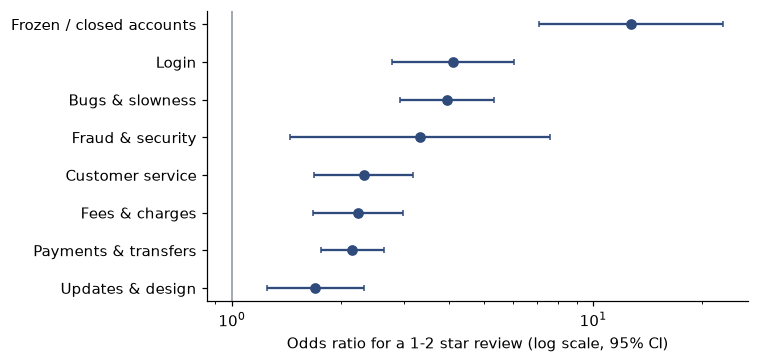

In [12]:
o = out.sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.errorbar(o.odds_ratio, range(len(o)), xerr=[o.odds_ratio - o.lo, o.hi - o.odds_ratio], fmt="o", color=NAVY, capsize=2)
ax.axvline(1, color=GREY, lw=1); ax.set_xscale("log"); ax.set_yticks(range(len(o)), [rv.SHORT[i] for i in o.index]); ax.set_xlabel("Odds ratio for a 1-2 star review (log scale, 95% CI)")
plt.tight_layout(); plt.savefig(FIG + "odds_ratios.png"); plt.show()

- **Frozen or closed accounts: odds ratio 12.8** (95% CI 7.1 to 23.0). A review that mentions an account being frozen, closed or restricted is far more likely to be a 1 or 2 star review than one that doesn't, whatever the app.
- **Login (4.1) and bugs (3.9)** come next, then **fraud or security (3.3, CI 1.5 to 7.6)**.
- **Customer service (2.3), fees (2.2) and payments (2.2)** are linked to low ratings, but less strongly than I predicted for customer service.
- **Updates and design (1.7, CI 1.3 to 2.3)** are the weakest link despite being the most common theme: many people mention a redesign without it driving the rating.
**What follows for priorities:** login and stability are both common and costly, so they come first. Account restrictions are rare at banks but the most damaging when they happen, so the process (explanation, appeal route, deadlines) is worth fixing even though it won't show up in volume. Redesigns draw many comments but less rating damage, so they are better handled with staged rollouts and an opt-out than with rework.

## 6. Does the fintech gap survive checks?
The fintech to bank ratio for frozen or closed accounts and for fraud or security, recomputed on longer reviews only, and leaving out each fintech app in turn (so that no single burst, such as Venmo's, drives the result):

In [13]:
def gap(df):
    fin = df.group == "Fintech & digital banks"
    return {c: df.loc[fin & df.low, c].mean() / max(df.loc[~fin & df.low, c].mean(), 1e-9) for c in ["Frozen, closed or restricted accounts", "Fraud, scams & security"]}
base = gap(d); rows = [{"scenario": "All apps", **{rv.SHORT[k]: v for k, v in base.items()}}]
rows.append({"scenario": "Reviews with 10+ words only", **{rv.SHORT[k]: v for k, v in gap(d[d.words >= 10]).items()}})
for app in d[d.group == "Fintech & digital banks"].app.unique():
    rows.append({"scenario": f"Leaving out {app}", **{rv.SHORT[k]: v for k, v in gap(d[d.app != app]).items()}})
pd.DataFrame(rows).set_index("scenario").round(2)

,Frozen / closed accounts,Fraud & security
scenario,,
All apps,2.68,3.46
Reviews with 10+ words only,2.72,3.25
Leaving out Chime,2.84,2.77
Leaving out Cash App,2.29,3.23
Leaving out PayPal,2.82,3.58
Leaving out Venmo,2.32,3.45
Leaving out SoFi,2.91,3.87
Leaving out Ally,2.92,3.93


The gap is stable: **2.3 to 2.9 times** for frozen or closed accounts and **2.8 to 3.9 times** for fraud or security under every variant, including reviews of ten or more words and leaving out Venmo, PayPal, Cash App, Chime, SoFi or Ally one at a time.

In [14]:
# Persist aggregated results (no review text) for the app
import os; os.makedirs("../data/processed", exist_ok=True)
by_app.assign(group=by_app.app.map(low.groupby("app").group.first())).to_csv("../data/processed/themes_by_app.csv", index=False)
prev_g.to_csv("../data/processed/themes_by_group.csv", index=False)
out.reset_index().rename(columns={"index": "theme"}).to_csv("../data/processed/odds_ratios.csv", index=False)
g.reset_index().to_csv("../data/processed/app_summary.csv", index=False)
resB.reset_index().to_csv("../data/processed/validation_scores_B.csv", index=False)
len(by_app)

136

## Findings
1. **Login and stability come first at banks:** 37% of unhappy bank reviews mention login or bugs, and each is linked to roughly four times the odds of a low rating.
2. **Account restrictions are the costliest theme:** odds ratio 12.8 although only 3% of bank reviews (10% at fintech) mention them.
3. **Redesigns are the most talked-about but least costly theme** (odds ratio 1.7).
4. **Fintech and payment-app reviewers write about frozen accounts (2.7 times) and fraud or security (3.5 times) far more than bank reviewers,** and the gap holds under every robustness check.
5. **Mean rating can't rank these apps:** it reflects how each app prompts happy users, not its quality.

## Predictions versus outcomes
| # | Prediction | Outcome |
|---|---|---|
| 1 | Login plus bugs in at least 30% of unhappy bank reviews | **Right:** 37% |
| 2 | Fintech at least twice the bank share for frozen accounts and for fraud or scams | **Right:** 2.7 times and 3.5 times |
| 3 | Customer service has the largest odds ratio | **Wrong:** it ranks fifth (2.3); frozen or closed accounts is first (12.8) |
| 4 | Tagger precision at least 0.8 for most themes, recall around 0.6 | **Partly wrong:** precision 0.8 or better for 4 of 9 themes (median 0.75); recall better than predicted (median 0.71) |
| 5 | Mean rating differs by over 1 star between best and worst app | **Right, but misleading:** 3.2 stars apart, mostly because of how apps prompt for ratings (revised in the plan before analysis) |

## Limits
- **iOS only, and only each app's 500 most recent reviews.** The time windows differ from 3 to 282 days, so each app is a snapshot.
- **Reviewers are self-selected** (people who write a review, mostly unhappy or very happy), not a sample of customers; mean ratings can't be compared across apps.
- **The tagger is rule-based and moderate in accuracy,** and my validation labels were made by an AI, not by a second human. Prevalence figures are approximate; between-group ratios are more reliable.
- **Odds ratios describe association,** not the effect of fixing a theme.
- **Per-app results rest on small samples** (U.S. Bank and Truist have under 50 unhappy reviews).
- **App reviews describe the app,** not the bank's service overall, and don't include Zelle, which has no standalone app.